# GMM initialization methods: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/mixture/plot_gmm_init.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/mixture/plot_gmm_init.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 4000 `make_blobs` points (4 centers, columns reversed). For each `init_params` in
`kmeans`, `random_from_data`, `k-means++`, `random`, one `np.random.RandomState(1234)` instance `r` is
created and passed as `random_state` to two consecutive estimators: a `max_iter=0` fit whose `means_` are
the initial means, then a `GaussianMixture(means_init=ini, tol=1e-9, max_iter=2000)` fit. Both consume the
same stream, so the second fit's KMeans initialization (used for the covariances) depends on how many
draws the first one consumed.

**Beyond the gallery:** full learned state of both fits (`weights_`, `covariances_`, `precisions_cholesky_`,
`lower_bound_`, `lower_bounds_`, `converged_`) and `predict`.

**Adaptations:**
- sklearn's "RandomState instance" `random_state` is Moxie's `fit_with_rng(X, rng)`, which borrows and
  advances a caller-owned `moxie._random.RandomState` (documented in `docs/mixture/gaussian/api.md`).
- `make_blobs` runs in Python and the data is shared; the relative initialization times are printed
  for both sides but not compared (Moxie makes no performance claim).

**Determinism:** deterministic (seeded MT19937 streams, single-threaded KMeans). Learned arrays,
iteration counts and labels are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("mixture/plot_gmm_init")

## 1. scikit-learn (Python reference)

In [2]:
from timeit import default_timer as timer

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets._samples_generator import make_blobs
from sklearn.mixture import GaussianMixture

X, y_true = make_blobs(n_samples=4000, centers=4, cluster_std=0.60, random_state=0)
X = X[:, ::-1]

methods = ["kmeans", "random_from_data", "k-means++", "random"]
sk = {}
for method in methods:
    r = np.random.RandomState(seed=1234)
    start = timer()
    init_model = GaussianMixture(
        n_components=4, init_params=method, tol=1e-9, max_iter=0, random_state=r
    ).fit(X)
    ini = init_model.means_
    init_time = timer() - start
    gmm = GaussianMixture(
        n_components=4, means_init=ini, tol=1e-9, max_iter=2000, random_state=r
    ).fit(X)
    sk[method] = dict(ini=ini, init_weights=init_model.weights_, init_cov=init_model.covariances_,
                      weights=gmm.weights_, means=gmm.means_, cov=gmm.covariances_,
                      prec_chol=gmm.precisions_cholesky_, n_iter=gmm.n_iter_,
                      lower_bound=gmm.lower_bound_, lower_bounds=np.array(gmm.lower_bounds_),
                      converged=gmm.converged_, pred=gmm.predict(X), time=init_time)
    print(f"{method:17s} n_iter_={gmm.n_iter_:3d} lower_bound_={gmm.lower_bound_:.10f} "
          f"init time {init_time / sk[methods[0]]['time']:.2f}x")
nb.share(X=X)

kmeans            n_iter_=  8 lower_bound_=-3.1667421901 init time 1.00x
random_from_data  n_iter_=137 lower_bound_=-3.3878128805 init time 0.04x


k-means++         n_iter_= 11 lower_bound_=-3.1667421901 init time 0.05x
random            n_iter_= 47 lower_bound_=-3.1667421900 init time 0.04x


## 2. Moxie (native Mojo)

The same two fits per method, sharing one `RandomState(1234)` through `fit_with_rng`.

In [3]:
%%mojo gmm_init
from std.time import perf_counter_ns
from numojo import NDArray
from moxie._random import RandomState
from moxie.mixture import GaussianMixture
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X = load("X")
    var methods: List[String] = ["kmeans", "random_from_data", "k-means++", "random"]
    var first_time = 0.0
    for m in range(len(methods)):
        var method = methods[m]
        var r = RandomState(1234)
        var start = perf_counter_ns()
        var init_model = GaussianMixture[DType.float64](4, init_params=method, tol=1e-9, max_iter=0)
        _ = init_model.fit_with_rng(X, r)
        var ini = init_model.means_.copy()
        var seconds = Float64(perf_counter_ns() - start) * 1e-9
        if m == 0:
            first_time = seconds
        var gmm = GaussianMixture[DType.float64](4, means_init=ini.copy(), tol=1e-9, max_iter=2000)
        _ = gmm.fit_with_rng(X, r)
        var tag = String(m)
        save("ini" + tag, ini)
        save("init_weights" + tag, init_model.weights_)
        save("init_cov" + tag, init_model.covariances_)
        save("weights" + tag, gmm.weights_)
        save("means" + tag, gmm.means_)
        save("cov" + tag, gmm.covariances_)
        save("prec_chol" + tag, gmm.precisions_cholesky_)
        save("pred" + tag, gmm.predict(X))
        save_floats("n_iter" + tag, [Float64(gmm.n_iter_)])
        save_floats("lower_bound" + tag, [gmm.lower_bound_])
        save_floats("lower_bounds" + tag, gmm.lower_bounds_)
        save_floats("converged" + tag, [1.0 if gmm.converged_ else 0.0])
        print(method, "n_iter_=", gmm.n_iter_, "lower_bound_=", gmm.lower_bound_,
              "init time", seconds / first_time, "x")

kmeans n_iter_= 8 lower_bound_= -3.166742190121745 init time 1.0 x
random_from_data n_iter_= 137 lower_bound_= -3.3878128805225525 init time 0.7734680513318087 x
k-means++ n_iter_= 11 lower_bound_= -3.166742190145731 init time 0.5871807618858234 x
random n_iter_= 47 lower_bound_= -3.1667421900498836 init time 0.6163848994243514 x


## 3. Side by side and parity

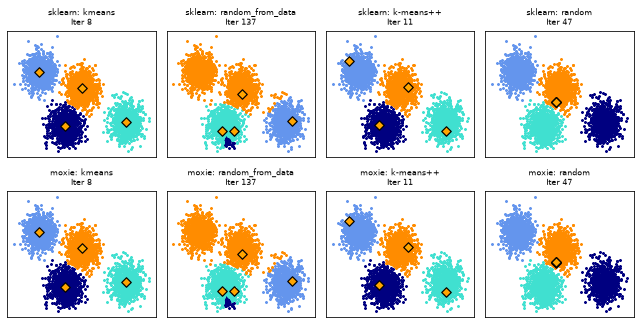

In [4]:
mx = nb.results["gmm_init"]
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6), dpi=72)
colors = ["navy", "turquoise", "cornflowerblue", "darkorange"]
for n, method in enumerate(methods):
    for row, (label, pred, ini, n_iter) in enumerate([
            ("sklearn", sk[method]["pred"], sk[method]["ini"], sk[method]["n_iter"]),
            ("moxie", mx[f"pred{n}"], mx[f"ini{n}"], int(mx[f"n_iter{n}"][0]))]):
        ax = axes[row, n]
        for i, color in enumerate(colors):
            data = X[pred == i]
            ax.scatter(data[:, 0], data[:, 1], color=color, marker="x", s=4)
        ax.scatter(ini[:, 0], ini[:, 1], s=45, marker="D", c="orange", lw=1.2, edgecolors="black")
        ax.set_xticks(()); ax.set_yticks(())
        ax.set_title(f"{label}: {method}\nIter {n_iter}", fontsize=8)
plt.tight_layout(); plt.show()

moxie_nb.side_by_side(
    sklearn=np.array([[sk[m]["n_iter"], sk[m]["lower_bound"]] for m in methods]),
    moxie=np.array([[mx[f"n_iter{n}"][0], mx[f"lower_bound{n}"][0]] for n in range(4)]))

reason_init = ("max_iter=0 state: same seeded draws and KMeans/k-means++ selections; Float64 statistics "
               "differ only by summation order (~1e-13 relative)")
reason_fit = ("up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding "
              "(~1e-15/step) stays below 1e-9 relative")
for n, method in enumerate(methods):
    s = sk[method]
    nb.compare(f"{method}: initial means_", s["ini"], mx[f"ini{n}"], rtol=1e-10, atol=1e-12, reason=reason_init)
    nb.compare(f"{method}: initial weights_", s["init_weights"], mx[f"init_weights{n}"], rtol=1e-10, atol=1e-12, reason=reason_init)
    nb.compare(f"{method}: initial covariances_", s["init_cov"], mx[f"init_cov{n}"], rtol=1e-9, atol=1e-12, reason=reason_init)
    nb.compare(f"{method}: n_iter_", s["n_iter"], mx[f"n_iter{n}"][0], exact=True)
    nb.compare(f"{method}: converged_", float(s["converged"]), mx[f"converged{n}"][0], exact=True)
    nb.compare(f"{method}: weights_", s["weights"], mx[f"weights{n}"], rtol=1e-9, atol=1e-12, reason=reason_fit)
    nb.compare(f"{method}: means_", s["means"], mx[f"means{n}"], rtol=1e-9, atol=1e-11, reason=reason_fit)
    nb.compare(f"{method}: covariances_", s["cov"], mx[f"cov{n}"], rtol=1e-8, atol=1e-11,
               reason=reason_fit + "; covariances are second moments, so rounding is squared")
    nb.compare(f"{method}: precisions_cholesky_", s["prec_chol"], mx[f"prec_chol{n}"], rtol=1e-8, atol=1e-10,
               reason=reason_fit + "; Cholesky of the covariance amplifies by its condition number")
    nb.compare(f"{method}: lower_bound_", s["lower_bound"], mx[f"lower_bound{n}"][0], rtol=1e-12, reason=reason_fit)
    nb.compare(f"{method}: lower_bounds_", s["lower_bounds"], mx[f"lower_bounds{n}"], rtol=1e-11, reason=reason_fit)
    nb.compare(f"{method}: predict", s["pred"], mx[f"pred{n}"], exact=True)
nb.note("init timings", "SKIP", "relative init times are printed for both sides; no performance claim is made")
nb.note("random_state=RandomState instance", "ADAPTED",
        "sklearn passes the RandomState object; Moxie borrows it through fit_with_rng (docs/mixture/gaussian/api.md)")

In [5]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
kmeans: initial means_,PASS,"(4, 2)","(4, 2)",3.55e-15,1.5e-15,"rtol=1e-10, atol=1e-12",,max_iter=0 state: same seeded draws and KMeans/k-means++ selections; Float64 statistics differ only by summation order (~1e-13 relative)
kmeans: initial weights_,PASS,"(4,)","(4,)",0,0,"rtol=1e-10, atol=1e-12",,max_iter=0 state: same seeded draws and KMeans/k-means++ selections; Float64 statistics differ only by summation order (~1e-13 relative)
kmeans: initial covariances_,PASS,"(4, 2, 2)","(4, 2, 2)",3.89e-16,7.03e-15,"rtol=1e-09, atol=1e-12",,max_iter=0 state: same seeded draws and KMeans/k-means++ selections; Float64 statistics differ only by summation order (~1e-13 relative)
kmeans: n_iter_,PASS,(),(),,,exact,0 mismatches,
kmeans: converged_,PASS,(),(),,,exact,0 mismatches,
kmeans: weights_,PASS,"(4,)","(4,)",1.11e-16,4.45e-16,"rtol=1e-09, atol=1e-12",,up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding (~1e-15/step) stays below 1e-9 relative
kmeans: means_,PASS,"(4, 2)","(4, 2)",3.64e-14,4.66e-15,"rtol=1e-09, atol=1e-11",,up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding (~1e-15/step) stays below 1e-9 relative
kmeans: covariances_,PASS,"(4, 2, 2)","(4, 2, 2)",1.05e-15,6.72e-14,"rtol=1e-08, atol=1e-11",,"up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding (~1e-15/step) stays below 1e-9 relative; covariances are second moments, so rounding is squared"
kmeans: precisions_cholesky_,PASS,"(4, 2, 2)","(4, 2, 2)",2.89e-15,6.88e-14,"rtol=1e-08, atol=1e-10",,up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding (~1e-15/step) stays below 1e-9 relative; Cholesky of the covariance amplifies by its condition number
kmeans: lower_bound_,PASS,(),(),6.22e-15,1.96e-15,"rtol=1e-12, atol=0",,up to 2000 EM iterations at tol=1e-9 from identical starts; summation-order rounding (~1e-15/step) stays below 1e-9 relative
